Saving Screenshot 2026-11-14 115946.png to Screenshot 2026-11-14 115946.png
Iteration: 1 Best Threshold: 177.61 Fitness: 7.821
Iteration: 2 Best Threshold: 177.61 Fitness: 7.821
Iteration: 3 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 4 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 5 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 6 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 7 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 8 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 9 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 10 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 11 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 12 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 13 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 14 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 15 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 16 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 17 Best Threshold: 178.39 Fitness: 7.8218
Iteration: 18 Best Threshold: 178.

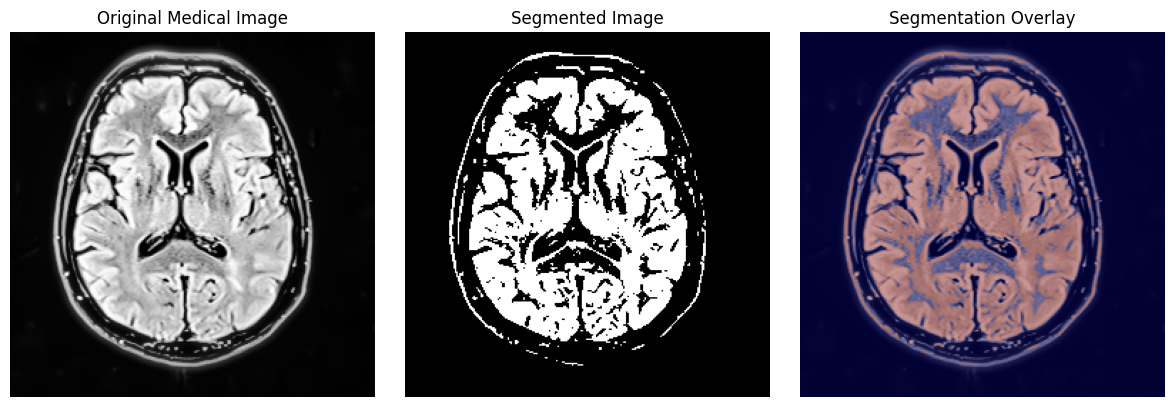

Optimal Threshold: 174
Best Fitness: 7.8222775


In [1]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
import math
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (256, 256))

n_nests = 25
pa = 0.25
iterations = 100
beta = 1.5

def fitness(threshold):
    threshold = int(np.clip(threshold, 1, 254))

    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).flatten()
    prob = hist / hist.sum()

    p1 = prob[:threshold]
    p2 = prob[threshold:]

    w1 = np.sum(p1)
    w2 = np.sum(p2)

    if w1 == 0 or w2 == 0:
        return 0

    p1 = p1 / w1
    p2 = p2 / w2

    e1 = -np.sum(p1[p1 > 0] * np.log(p1[p1 > 0]))
    e2 = -np.sum(p2[p2 > 0] * np.log(p2[p2 > 0]))

    return e1 + e2

def levy_flight(beta):
    sigma = (
        math.gamma(1 + beta) *
        np.sin(np.pi * beta / 2) /
        (math.gamma((1 + beta) / 2) *
         beta * 2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    step = u / (abs(v) ** (1 / beta) + 1e-10)

    return 0.01 * step

nests = np.random.uniform(1, 254, n_nests)

best_threshold = 0
best_fitness = -np.inf

for iteration in range(iterations):

    for i in range(n_nests):

        new_solution = nests[i] + levy_flight(beta) * (
            nests[i] - nests[np.random.randint(n_nests)]
        )

        new_solution = np.clip(new_solution, 1, 254)

        if fitness(new_solution) > fitness(nests[i]):
            nests[i] = new_solution

    fitness_values = np.array([fitness(n) for n in nests])

    abandon_count = int(pa * n_nests)

    worst_indices = np.argsort(fitness_values)[:abandon_count]

    nests[worst_indices] = np.random.uniform(
        1, 254, abandon_count
    )

    fitness_values = np.array([fitness(n) for n in nests])

    best_index = np.argmax(fitness_values)

    if fitness_values[best_index] > best_fitness:
        best_fitness = fitness_values[best_index]
        best_threshold = nests[best_index]

    print("Iteration:", iteration + 1,
          "Best Threshold:", round(best_threshold, 2),
          "Fitness:", round(best_fitness, 4))

best_threshold = int(best_threshold)

_, segmented_image = cv2.threshold(
    image, best_threshold, 255, cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Medical Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title("Segmented Image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(image, cmap='gray')
plt.imshow(segmented_image, cmap='jet', alpha=0.4)
plt.title("Segmentation Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Optimal Threshold:", best_threshold)
print("Best Fitness:", best_fitness)
